# Alteração para utilizar a GPU do google colab

In [ ]:
!git clone https://github.com/rapidsai/rapidsai-csp-utils.git
!python rapidsai-csp-utils/colab/pip-install.py

fatal: destination path 'rapidsai-csp-utils' already exists and is not an empty directory.
Installing RAPIDS remaining 26.06 libraries
Using Python 3.13.16 environment at: /usr
Checked 11 packages in 98ms

        ***********************************************************************
        The pip install of RAPIDS is complete.

        Please do not run any further installation from the conda based installation methods, as they may cause issues!

        Please ensure that you're pulling from the git repo to remain updated with the latest working install scripts.

        Troubleshooting:
            - If there is an installation failure, please check back on RAPIDSAI owned templates/notebooks to see how to update your personal files.
            - If an installation failure persists when using the latest script, please make an issue on https://github.com/rapidsai-community/rapidsai-csp-utils
        ***********************************************************************
        


In [ ]:
import cudf as pd
from cuml.ensemble import RandomForestClassifier
from cuml.model_selection import GridSearchCV
from cuml.metrics import r2_score
from cuml.preprocessing import LabelEncoder
from cuml.preprocessing import MinMaxScaler
from cuml.model_selection import train_test_split


import warnings
warnings.filterwarnings("ignore")

import time

In [ ]:
!nvidia-smi

Tue Oct 27 12:49:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   62C    P0             31W /   70W |     795MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

                 Dataset Kaggle
                        │
                        ▼
               Análise Exploratória
                        │
                        ▼
          Engenharia de Características
                        │
                        ▼
             Divisão Treino/Teste
                        │
                        ▼
                 Modelo Baseline
             (Logistic Regression)
                        │
                        ▼
               Modelos Ensemble
          ┌──────────┬───────────┐
          │          │           │
          ▼          ▼           ▼
   Random Forest   XGBoost   Comparação
          │          │
          └────┬─────┘
               ▼
        GridSearchCV
               │
               ▼
        Melhor Modelo
               │
               ▼
         Salvamento (.pkl)
               │
               ▼
         Script de Predição
               │
               ▼
     Monitoramento e Atualização

In [ ]:
%%time
df_inicial = pd.read_csv('creditcard.csv')
df_inicial.shape

CPU times: user 98.2 ms, sys: 56 ms, total: 154 ms
Wall time: 131 ms


(284807, 31)

In [ ]:
df_inicial.head(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
df_inicial.info()

<class 'cudf.core.dataframe.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     2848

In [ ]:
df_inicial.shape

(284807, 31)

### Tratamento de valores ausentes

- Antes de qualquer modelagem é necessário verificar a existência de dados faltantes.


In [ ]:
df_inicial.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

### Analise
- Neste dataset possui valores nulos
- Iremos removelos.


In [ ]:
df = df_inicial.dropna()

In [ ]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

# Normalização

- StandardScaler


In [ ]:
#from sklearn.preprocessing import StandardScaler
from cuml.preprocessing import StandardScaler

scaler = StandardScaler()

#rename colunm
df['Amount_Scaled'] = scaler.fit_transform(
    df[['Amount']]
)
#rename colunm
df['Time_Scaled'] = scaler.fit_transform(
    df[['Time']]
)

# Tranformação datetime para horas normais

- A variavel time representa seugundos desde a primeira transação registrada. Podemos transforma-la numa insformação com maior siginificado para o modelo.


In [ ]:
df['Hours'] = (df['Time'] // 3600) % 24

In [ ]:
df['Hours']

0          0.0
1          0.0
2          0.0
3          0.0
4          0.0
          ... 
284802    23.0
284803    23.0
284804    23.0
284805    23.0
284806    23.0
Name: Hours, Length: 284807, dtype: float64

### Categorização das horas
0 - 5 Madrugada
6 - 11 Manhã
12 - 17 Tarde
18 - 23 Noite

In [ ]:


# Definimos os limites dos intervalos (bins)
bins = [-1, 5, 11, 17, 24]
labels = ['Madrugada', 'Manhã', 'Tarde', 'Noite']

# Criamos a categoria de período como strings
df['Period'] = pd.cut(df['Hours'], bins=bins, labels=labels)

# Para evitar problemas com tipos 'object' na GPU, convertemos
# a categoria em valores numéricos (0, 1, 2, 3)
df['Period'] = df['Period'].astype('category').cat.codes

In [ ]:
df['Period']

0         0
1         0
2         0
3         0
4         0
         ..
284802    3
284803    3
284804    3
284805    3
284806    3
Name: Period, Length: 284807, dtype: uint8

### Tranformação One-Hot-Encoding

- Adicionaremos as tres categorias na tabela.
- Em valor boleanos


In [ ]:
df = pd.get_dummies(
  df,
  columns=['Period'],
  drop_first=True
)

In [ ]:
df.head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V27,V28,Amount,Class,Amount_Scaled,Time_Scaled,Hours,Period_1,Period_2,Period_3
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.133558,-0.021053,149.62,0,0.244964,-1.996583,0.0,False,False,False
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.008983,0.014724,2.69,0,-0.342475,-1.996583,0.0,False,False,False
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,-0.055353,-0.059752,378.66,0,1.160686,-1.996562,0.0,False,False,False
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,0.062723,0.061458,123.50,0,0.140534,-1.996562,0.0,False,False,False
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.219422,0.215153,69.99,0,-0.073403,-1.996541,0.0,False,False,False
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,0.253844,0.081080,3.67,0,-0.338556,-1.996541,0.0,False,False,False
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,...,0.034507,0.005168,4.99,0,-0.333279,-1.996499,0.0,False,False,False
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,-1.206921,-1.085339,40.80,0,-0.190107,-1.996436,0.0,False,False,False
8,7.0,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,0.011747,0.142404,93.20,0,0.019392,-1.996436,0.0,False,False,False
9,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,...,0.246219,0.083076,3.68,0,-0.338516,-1.996394,0.0,False,False,False


## Treino e Teste


In [ ]:
# Definindo o target
X = df.drop('Class', axis=1)

# Convertendo a coluna Class para tipo numérico (int32) para evitar o erro de 'OBJECT array' na GPU
y = df['Class'].astype('int32')

# Importando o train_test_split do cuML
from cuml.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

O SMOTE (Synthetic Minority Over-sampling Technique) é uma técnica usada para balancear classes desbalanceadas.

In [ ]:
import cudf
import cupy as cp
from imblearn.over_sampling import SMOTE

# Converte para CPU (pandas)
X_cpu = X_train.to_pandas()
y_cpu = y_train.to_pandas()

X_resampled, y_resampled = SMOTE(random_state=42).fit_resample(X_cpu, y_cpu)


In [ ]:
X_resampled_gpu = pd.DataFrame(X_resampled)
y_resampled_gpu = pd.Series(y_resampled)


In [ ]:


''' from numpy import random
from imblearn.over_sampling import SMOTE
#from cuml.over_sampling import SMOTE


X_resampled, y_resampled = SMOTE(
    random_state=42
).fit_resample(
    X_train, y_train) '''

' from numpy import random\nfrom imblearn.over_sampling import SMOTE\n#from cuml.over_sampling import SMOTE\n\n\nX_resampled, y_resampled = SMOTE(\n    random_state=42\n).fit_resample(\n    X_train, y_train) '

# Logistic Regression

- Regressão Lojistica é muito utilizada em datasets de classificação binaria.



In [ ]:
%%time
from cuml.linear_model import LogisticRegression

lr_model = LogisticRegression(
    #random_state=42,
    max_iter=1000,
    fit_intercept=True,

)
lr_model.fit(X_resampled, y_resampled)

''' from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    random_state=42,
    max_iter=1000,

)
lr_model.fit(X_resampled, y_resampled) '''

CPU times: user 763 ms, sys: 32.7 ms, total: 795 ms
Wall time: 798 ms


' from sklearn.linear_model import LogisticRegression\n\nlr_model = LogisticRegression(\n    random_state=42,\n    max_iter=1000,\n\n)\nlr_model.fit(X_resampled, y_resampled) '

In [ ]:
y_pred_lr = lr_model.predict(X_test)

y_prob_lr = lr_model.predict_proba(X_test)[1]

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test.to_pandas(),
    y_pred_lr.to_pandas()
))


              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.07      0.91      0.13        98

    accuracy                           0.98     56962
   macro avg       0.54      0.94      0.56     56962
weighted avg       1.00      0.98      0.99     56962



# Random Forest
- Arvores aleatorias combina diversas arvores de decisão para reduzir overfitting e aumentar a capacidade preditiva.


In [ ]:
#from sklearn.ensemble import RandomForestClassifier
from cuml.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators = 100,
)


In [ ]:
%%time
rf_model.fit(
    X_resampled,
    y_resampled
)




CPU times: user 3.88 s, sys: 1.56 s, total: 5.44 s
Wall time: 2.88 s


RandomForestClassifier()

In [ ]:
%%time
y_pred_rf = rf_model.predict(X_test)

# No cuML, o predict_proba retorna um DataFrame cuDF.
# Acessamos a probabilidade da classe positiva selecionando diretamente a coluna pelo rótulo dela (1).
y_prob_rf = rf_model.predict_proba(X_test)[1]

CPU times: user 80.7 ms, sys: 3.7 ms, total: 84.4 ms
Wall time: 85.3 ms


# Analise do  Random Forest
- com 100 n_estimators demorou mais de 12 mim para rodar
- reduziremos os promixos. Mas sera que ira mudar a precisao do proximo algoritmo?

# Com a mudança para gpu tivemos um salto enorme de 12 min para 5 segundos.

XGBoost

- XGBoost é um dos algoritmos mais utilizados em recontrução de arvores, corrigindo os erros anteriores.


In [ ]:
!pip install xgboost -q


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    tree_method='hist',       # Método padrão unificado
    device='cuda',            # Ativa explicitamente o uso da GPU (CUDA)
    n_estimators=50,
    random_state=42,
    eval_metric='logloss'
)

print(xgb_model.get_params())

{'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': 'cuda', 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': None, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 50, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': 'hist', 'validate_parameters': None, 'verbosity': None}


In [ ]:
%%time
xgb_model.fit(
    X_resampled,
    y_resampled

)

CPU times: user 4.73 s, sys: 17.4 ms, total: 4.75 s
Wall time: 2.76 s


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device='cuda', early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=50, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:

%%time
y_pred_xgb = xgb_model.predict(X_test)

y_prob_xgb = xgb_model.predict_proba(X_test)[:,1]

CPU times: user 27.2 ms, sys: 2.85 ms, total: 30 ms
Wall time: 25.1 ms


# Avaliação dos modelos

- Sera criada uma função para não ficar repetindo. (DRY)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_model(y_true, y_pred, y_prob):
    # Convertemos os dados para CPU (numpy) caso ainda estejam na GPU (cuDF/cupy)
    y_t = y_true.to_numpy() if hasattr(y_true, 'to_numpy') else y_true
    y_p = y_pred.to_numpy() if hasattr(y_pred, 'to_numpy') else y_pred
    y_pb = y_prob.to_numpy() if hasattr(y_prob, 'to_numpy') else y_prob

    return {
        "Accuracy": accuracy_score(y_t, y_p),
        "Precision": precision_score(y_t, y_p),
        "Recall": recall_score(y_t, y_p),
        "F1": f1_score(y_t, y_p),
        "ROC_AUC": roc_auc_score(y_t, y_pb)
    }

# Logistic Regression


In [ ]:
lr_results = evaluate_model(
    y_test,
    y_pred_lr,
    y_prob_lr
)

lr_results

{'Accuracy': 0.9793722130543169,
 'Precision': 0.07091633466135458,
 'Recall': 0.9081632653061225,
 'F1': 0.13155949741315595,
 'ROC_AUC': np.float64(0.973796681376546)}

# Random Forest

In [ ]:
rf_results = evaluate_model(
    y_test,
    y_pred_rf,
    y_prob_rf
)

rf_results

{'Accuracy': 0.9991924440855307,
 'Precision': 0.7321428571428571,
 'Recall': 0.8367346938775511,
 'F1': 0.780952380952381,
 'ROC_AUC': np.float64(0.9756228251007776)}

# XGBoost

In [ ]:
xgb_results = evaluate_model(
    y_test,
    y_pred_xgb,
    y_prob_xgb
)

xgb_results


{'Accuracy': 0.9991748885221726,
 'Precision': 0.7142857142857143,
 'Recall': 0.8673469387755102,
 'F1': 0.783410138248848,
 'ROC_AUC': np.float64(0.9836555964535504)}

# Comparação dos resultados

- apos treinamentos
- transformaremos em um df

In [ ]:
results = pd.DataFrame([
    lr_results,
    rf_results,
    xgb_results
])

results.index = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
]

results

,Accuracy,Precision,Recall,F1,ROC_AUC
Logistic Regression,0.979372,0.070916,0.908163,0.131559,0.973797
Random Forest,0.999192,0.732143,0.836735,0.780952,0.975623
XGBoost,0.999175,0.714286,0.867347,0.783410,0.983656


# Analise dos dados

- Baseando no Reccal como criterio principal seguido de F1 e ROC.

- Melhor modelo foi o **XGBoost**. Gerando menos falsos positivos.

- Apesar do Logistic Regression ter uma Recall superior. Ele gerou 428 falsos positivos, sendo assim foi descartado.



# Matriz de confusão

- Matriz de confusão conseguimos ver os TP FP.


XGBoost

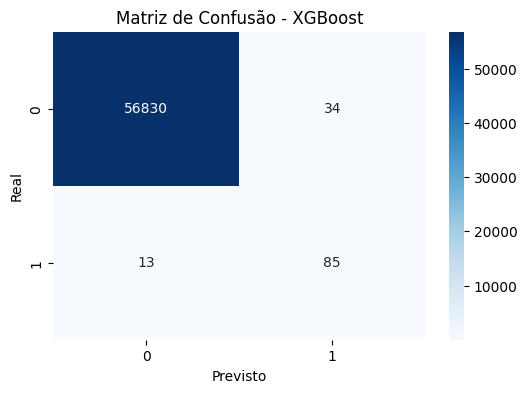

In [ ]:
from cuml.metrics import confusion_matrix as cuml_confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculamos a matriz de confusão usando a GPU via cuML
cm_gpu = cuml_confusion_matrix(
    y_test,
    y_pred_xgb
)

# Como cm_gpu é um array CuPy na GPU, usamos .get() para copiá-lo para a CPU como um array NumPy
cm_cpu = cm_gpu.get()

plt.figure(figsize=(6,4))
sns.heatmap(
    cm_cpu,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Matriz de Confusão - XGBoost")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.show()

# DRY para Matriz

In [ ]:
from cuml.metrics import confusion_matrix as cuml_confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def plot_confusion_matrix(model_name, y_true, y_pred):
    # Calculamos de forma extremamente rápida na GPU com cuML
    cm_gpu = cuml_confusion_matrix(y_true, y_pred)

    # Transferimos explicitamente o resultado para a CPU (.get()) para o Seaborn desenhar o gráfico
    cm_cpu = cm_gpu.get()

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm_cpu,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Normal', 'Fraude'],
        yticklabels=['Normal', 'Fraude']
    )

    plt.title(f'Matriz de Confusão - {model_name}')
    plt.xlabel('Classe Prevista')
    plt.ylabel('Classe Real')

    plt.tight_layout()
    plt.show()

In [ ]:
predictions = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

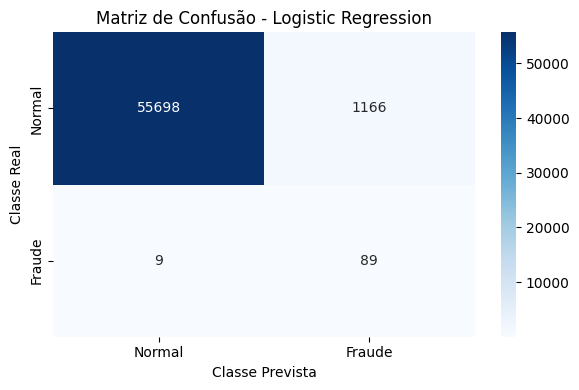

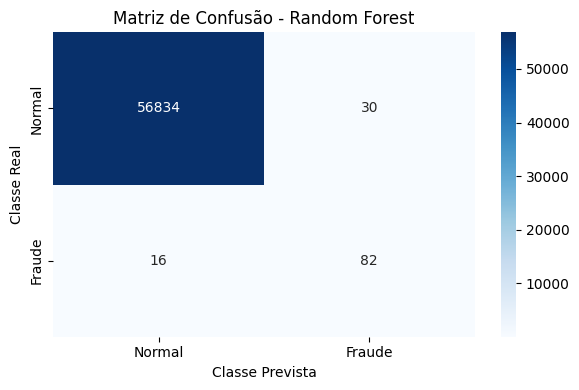

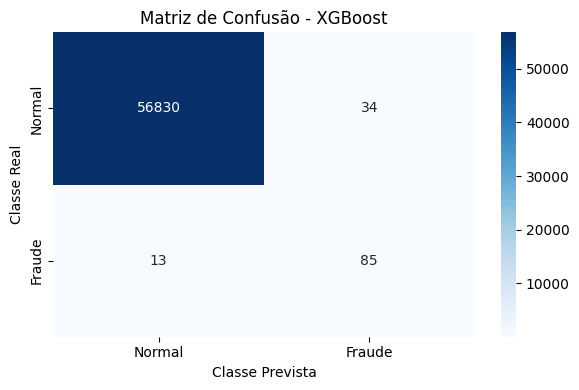

In [ ]:
for model_name, y_pred in predictions.items():
    plot_confusion_matrix(
        model_name,
        y_test,
        y_pred
    )

# Curva de ROC

- Compara o desempenho dos modelos.


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

def plot_roc_curve(models_probs, y_true):
    plt.figure(figsize=(8, 6))

    # Garante que o y_true (real) seja convertido de forma explícita para CPU (NumPy)
    y_true_cpu = y_true.to_numpy() if hasattr(y_true, 'to_numpy') else y_true

    for model_name, y_prob in models_probs.items():
        # Garante que as probabilidades também sejam convertidas explicitamente para CPU
        if hasattr(y_prob, 'to_numpy'):
            y_prob_cpu = y_prob.to_numpy()
        elif hasattr(y_prob, 'get'):
            y_prob_cpu = y_prob.get()
        else:
            y_prob_cpu = y_prob

        # Agora calculamos de forma segura na CPU usando as funções do scikit-learn
        fpr, tpr, _ = roc_curve(y_true_cpu, y_prob_cpu)
        auc = roc_auc_score(y_true_cpu, y_prob_cpu)

        plt.plot(
            fpr,
            tpr,
            label=f'{model_name} (AUC={auc:.3f})'
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        color='gray'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Comparação ROC')
    plt.legend()
    plt.grid(True)
    plt.show()

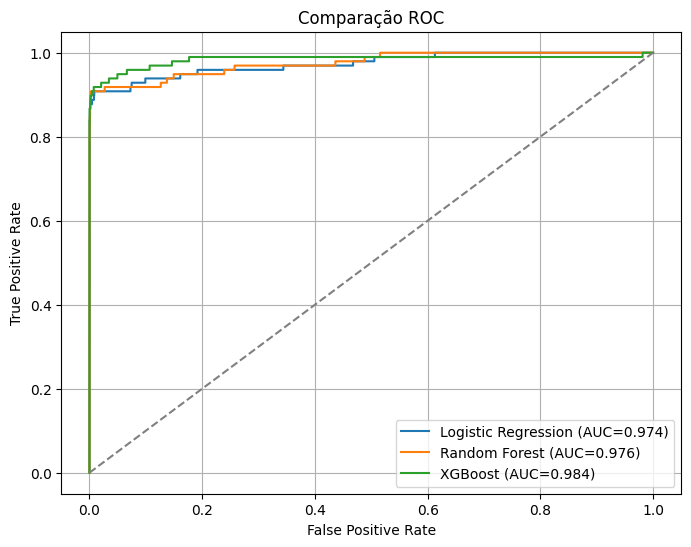

In [ ]:
models_probs = {
    "Logistic Regression": y_prob_lr,
    "Random Forest": y_prob_rf,
    "XGBoost": y_prob_xgb
}

plot_roc_curve(
    models_probs,
    y_test
)

In [ ]:
#from sklearn.metrics import confusion_matrix
from cuml.metrics import confusion_matrix as cuml_confusion_matrix
def get_confusion_metrics(y_true, y_pred):

    tn, fp, fn, tp = cuml_confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    return {
        'TN (Normal→Normal)': tn,
        'FP (Normal→Fraude)': fp,
        'FN (Fraude→Normal)': fn,
        'TP (Fraude→Fraude)': tp
    }

In [ ]:
cm_results = pd.DataFrame({
    'Logistic Regression': get_confusion_metrics(y_test, y_pred_lr),
    'Random Forest': get_confusion_metrics(y_test, y_pred_rf),
    'XGBoost': get_confusion_metrics(y_test, y_pred_xgb)
}).T

cm_results

,TN (Normal→Normal),FP (Normal→Fraude),FN (Fraude→Normal),TP (Fraude→Fraude)
Logistic Regression,55698,1166,9,89
Random Forest,56834,30,16,82
XGBoost,56830,34,13,85


In [ ]:
# Importamos as métricas do scikit-learn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import numpy as np

# Convertemos explicitamente os targets e previsões de GPU para CPU (NumPy)
y_test_cpu = y_test.to_numpy()

# Previsões
y_pred_lr_cpu = y_pred_lr.to_numpy() if hasattr(y_pred_lr, 'to_numpy') else y_pred_lr
y_pred_rf_cpu = y_pred_rf.to_numpy() if hasattr(y_pred_rf, 'to_numpy') else y_pred_rf
y_pred_xgb_cpu = y_pred_xgb.get() if hasattr(y_pred_xgb, 'get') else y_pred_xgb

# Probabilidades
y_prob_lr_cpu = y_prob_lr.to_numpy() if hasattr(y_prob_lr, 'to_numpy') else y_prob_lr
y_prob_rf_cpu = y_prob_rf.to_numpy() if hasattr(y_prob_rf, 'to_numpy') else y_prob_rf
y_prob_xgb_cpu = y_prob_xgb.get() if hasattr(y_prob_xgb, 'get') else y_prob_xgb

# Construção do DataFrame utilizando dados na CPU
comparison_df = pd.DataFrame({
    "Accuracy": [
        accuracy_score(y_test_cpu, y_pred_lr_cpu),
        accuracy_score(y_test_cpu, y_pred_rf_cpu),
        accuracy_score(y_test_cpu, y_pred_xgb_cpu)
    ],
    "Precision": [
        precision_score(y_test_cpu, y_pred_lr_cpu),
        precision_score(y_test_cpu, y_pred_rf_cpu),
        precision_score(y_test_cpu, y_pred_xgb_cpu)
    ],
    "Recall": [
        recall_score(y_test_cpu, y_pred_lr_cpu),
        recall_score(y_test_cpu, y_pred_rf_cpu),
        recall_score(y_test_cpu, y_pred_xgb_cpu)
    ],
    "F1": [
        f1_score(y_test_cpu, y_pred_lr_cpu),
        f1_score(y_test_cpu, y_pred_rf_cpu),
        f1_score(y_test_cpu, y_pred_xgb_cpu)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test_cpu, y_prob_lr_cpu),
        roc_auc_score(y_test_cpu, y_prob_rf_cpu),
        roc_auc_score(y_test_cpu, y_prob_xgb_cpu)
    ]
},
index=[
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
])

comparison_df = comparison_df.join(cm_results)
comparison_df

,Accuracy,Precision,Recall,F1,ROC_AUC,TN (Normal→Normal),FP (Normal→Fraude),FN (Fraude→Normal),TP (Fraude→Fraude)
Logistic Regression,0.979372,0.070916,0.908163,0.131559,0.973797,55698,1166,9,89
Random Forest,0.999192,0.732143,0.836735,0.780952,0.975623,56834,30,16,82
XGBoost,0.999175,0.714286,0.867347,0.783410,0.983656,56830,34,13,85


# Analise dos resultados

- Como resaltado antes o Random Forest deve um desempenho melhor, trazendo 14 fraudes perdidas e apenas 8 alarme falsos, em comparação com Logist Regression que teve 481. Apesar de ter perdido apenas 9. Mas fazer 481 clientes passar por contragimento, não vale a pena.

## com modificaçao para GPU o **XGBoost** ficou melhor.




# Parte 04 - Avaliação e Melhoria do Modelo.

- Realizar ajuste de hiperparâmetros para melhorar seu desempenho.

Para esse parte podiamos utilizar as analises feitas no final da parte 3, onde foi feito as analises e as comparações.

- E foi decidido para fazer a otimização foi o **random forest**



## Otimização com GridSearchCV

# Utilizando a GPU para poder fazer essa hiperparametro.

## Importações palaca usar o GPU do google  colab

In [ ]:
''' param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
} '''

In [ ]:
%%time
from cuml.ensemble import RandomForestClassifier
from cuml.model_selection import GridSearchCV
import cudf

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30],
    'max_features': ['auto', 'sqrt']
}

rf = RandomForestClassifier()

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='f1',
    cv=3
)

# Convertendo explicitamente para arrays NumPy para evitar conversão implícita do Scikit-Learn interno do cuML
X_resampled_np = X_resampled_gpu.to_numpy()
y_resampled_np = y_resampled_gpu.to_numpy()

grid_search.fit(X_resampled_np, y_resampled_np)

CPU times: user 2min 33s, sys: 59 s, total: 3min 32s
Wall time: 2min


GridSearchCV(cv=3, estimator=RandomForestClassifier(),
             param_grid={'max_depth': [10, 20, 30],
                         'max_features': ['auto', 'sqrt'],
                         'n_estimators': [100, 200, 300]},
             scoring='f1')

In [ ]:
# Acessando os melhores parâmetros e a melhor pontuação obtida no GridSearchCV do cuML
try:
    print("Melhores Parâmetros:", grid_search.best_params_)
    print("Melhor Score (F1):", grid_search.best_score_)
except AttributeError:
    # Caso o cuML tenha estruturado o resultado de forma diferente nesta versão,
    # podemos extrair diretamente do cv_results_
    import pandas as pd_cpu
    df_results = pd_cpu.DataFrame(grid_search.cv_results_)
    best_row = df_results.sort_values(by='mean_test_score', ascending=False).iloc[0]
    print("Melhores Parâmetros (via cv_results):", best_row['params'])
    print("Melhor Score (F1) associado:", best_row['mean_test_score'])

Melhores Parâmetros: {'max_depth': 30, 'max_features': 'sqrt', 'n_estimators': 200}
Melhor Score (F1): 0.9998966932919369


In [ ]:
grid_search.best_estimator_

RandomForestClassifier()

# Salvando o melhor modelo.

- Utilizaremos o pickle, salvando o melhor.


In [ ]:
import pickle

model_info = {
    "model": grid_search.best_estimator_,
    "best_params": grid_search.best_params_,
    "best_score": grid_search.best_score_
}

with open('fraud_model.pkl', 'wb') as file:
    pickle.dump(model_info, file)

print("Melhor modelo e parâmetros salvos!")


Melhor modelo e parâmetros salvos!


# Reutilizando o modelo

- Abriremos o arquivo salvo.


In [ ]:
with open('fraud_model.pkl', 'rb') as f:
    data = pickle.load(f)

    model = data["model"]


print(type(data))
print(data.keys())
print("Melhores parâmetros:", data["best_params"])
print("Melhor F1:", data["best_score"])

<class 'dict'>
dict_keys(['model', 'best_params', 'best_score'])
Melhores parâmetros: {'max_depth': 30, 'max_features': 'sqrt', 'n_estimators': 200}
Melhor F1: 0.9998966932919369


In [ ]:
print(X_resampled_gpu.columns)

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Amount_Scaled', 'Time_Scaled', 'Hours', 'Period_1', 'Period_2',
       'Period_3'],
      dtype='object')


In [ ]:
print(X_resampled_gpu.shape)

(454902, 36)


## Fazendo uma previsão!



In [ ]:
novo_dado = X_resampled_gpu.iloc[:1]

pred = model.predict(novo_dado)

print(pred)

0    0
dtype: int32


In [ ]:
print("Real:", y_resampled_gpu.iloc[0])
print("Previsto:", pred[0])

Real: 0
Previsto: 0


In [ ]:
amostra = X_resampled_gpu.iloc[:10]

preds = model.predict(amostra)

preds_np = preds.to_numpy()

for i, p in enumerate(preds_np):
    print(f"Linha {i}: {p}")

Linha 0: 0
Linha 1: 0
Linha 2: 0
Linha 3: 0
Linha 4: 0
Linha 5: 0
Linha 6: 0
Linha 7: 0
Linha 8: 0
Linha 9: 0


In [ ]:
from sklearn.metrics import accuracy_score

preds = model.predict(amostra).to_numpy()
reais = y_resampled_gpu.iloc[:10].to_numpy()

print("Accuracy:", accuracy_score(reais, preds))

Accuracy: 1.0


In [ ]:
nova = X_test.iloc[[0]].copy()

nova['Amount'] = 99555
nova['Hours'] = 3

pred = model.predict(nova)

print(pred.to_numpy())

[0]


# Teste em varias utilizações

In [ ]:
import random

for _ in range(10):
    nova = X_test.iloc[[0]].copy()

    nova['Amount'] = random.randint(5000, 15000)
    nova['Hours'] = random.randint(1, 24)

    pred = model.predict(nova)

    valor_pred = pred.iloc[0]

    print(
        f"Amount={nova['Amount'].iloc[0]}, "
        f"Hours={nova['Hours'].iloc[0]}, "
        f"Pred={valor_pred}"
    )

Amount=7915, Hours=21, Pred=0
Amount=11176, Hours=15, Pred=0
Amount=10119, Hours=4, Pred=0
Amount=14567, Hours=5, Pred=0
Amount=11065, Hours=2, Pred=0
Amount=9222, Hours=17, Pred=0
Amount=5106, Hours=2, Pred=0
Amount=12991, Hours=22, Pred=0
Amount=6490, Hours=6, Pred=0
Amount=13759, Hours=22, Pred=0


In [ ]:
print(type(pred))
print(pred)


<class 'cudf.core.series.Series'>
263020    0
dtype: int32




## Monitoramento

- o modelo poderia ser monitorado através:
  - recall
  - precision
  - F1-Score
  - Taxa de falsos positivos
  - Taxa de falsos negativos
Caso as metricas apresentem degradação ao longo do tempo, uma nova versão do modelo deverá ser treinada.

## Data Drift
As distribuições das variaveis podem sofrer alterações com o passar do tempo.

Exemplos:
 - Mudança no comportamento dos clientes
 - Novos tipos de fraudes
 - Mudanças regionais ou sazonais

Uma estratégia simples de atualização seria:

Coleta de novos dados ->
Validação da qualidade ->

Reprocessamento ->

Retreinamento ->

Avaliação ->

Publicação da nova


## Versionamento
- Github
- salvando o modelo gerado com versoes diferentes
fraud_model_v1.pkl
fraud_model_v2.pkl
fraud_model_v3.pkl




# Parte 6 – Conclusões

## Resumo do Projeto

Neste projeto foi desenvolvido um sistema de deteção de fraudes em transações de cartão de crédito utilizando técnicas de Machine Learning.

O conjunto de dados utilizado foi o Credit Card Fraud Detection Dataset, disponibilizado através da plataforma [Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud).

Durante a fase de preparação dos dados foram realizadas diversas transformações e tratamentos com o objetivo de melhorar a qualidade dos dados para os modelos de Machine Learning. Entre as principais transformações realizadas destacam-se:

  - Verificação e tratamento de valores nulos e ausentes;
  - Conversão da variável Time, originalmente representada em segundos, para horas;
  - Normalização das variáveis numéricas;
  - Separação dos dados em conjuntos de treino e teste;
  - Balanceamento das classes utilizando técnicas adequadas para lidar com o problema de desbalanceamento.

Foram treinados três modelos de classificação:

- Regressão Logística;
- Random Forest;
- XGBoost.

Posteriormente, os modelos foram comparados através das métricas:

- Accuracy (Acurácia);
- Precision (Precisão);
- Recall; # Metrica decisiva para o melhor modelo
- F1-Score;
- ROC-AUC.

Os resultados mostraram que o modelo Random Forest apresentou o melhor equilíbrio entre deteção de fraudes e redução de falsos positivos, alcançando os melhores resultados gerais de Precision e F1-Score.

## Otimização do Modelo

Após a comparação inicial dos modelos, o Random Forest foi selecionado para a etapa de otimização utilizando o método GridSearchCV.

Os melhores hiperparâmetros encontrados foram:
```
Python
{
'max_depth': 30,
'max_features': 'sqrt',
'n_estimators': 200
}
```


Obtendo um score F1 de: *0.9998966932919369*

A otimização permitiu melhorar o desempenho do modelo e encontrar uma configuração mais adequada para o problema de deteção de fraudes.

### MLOps

Como parte das práticas de MLOps, o modelo final foi armazenado em ficheiro utilizando o formato Pickle (.pkl), permitindo o seu carregamento posterior sem necessidade de novo treino.

Também foi desenvolvido um script simples de carregamento e predição, permitindo realizar inferências sobre novas transações.

Foram ainda realizados testes com novas amostras para validar o correto funcionamento do modelo serializado.

### Limitações Encontradas

Durante o desenvolvimento do projeto foram identificadas algumas dificuldades, principalmente relacionadas com:

- Escolha de hiperparâmetros;
- Processo de otimização dos modelos;
- Interpretação das métricas de avaliação;
- Seleção dos algoritmos mais adequados para cada problema.

Estas dificuldades fazem parte do processo de aprendizagem em Machine Learning e contribuíram para uma melhor compreensão das etapas envolvidas na construção de modelos preditivos.

### Trabalhos Futuros

Como melhorias futuras, destacam-se:

- Utilizar aceleração por GPU para reduzir o tempo de treino dos modelos;
- Explorar algoritmos adicionais de Ensemble Learning;
- Implementar uma API para disponibilizar o modelo online;
- Realizar deploy do modelo em serviços cloud;
- Implementar monitorização automática para deteção de queda de desempenho (model drift);
- Estudar técnicas mais avançadas de otimização de hiperparâmetros, como: - RandomizedSearchCV e Optuna.
Conclusão Final

O projeto permitiu aplicar conceitos de preparação de dados, engenharia de características, modelos ensemble, avaliação de desempenho, otimização de hiperparâmetros e práticas básicas de MLOps. Os resultados obtidos demonstraram que modelos ensemble, especialmente o Random Forest, são capazes de alcançar elevado desempenho em problemas de deteção de fraude, constituindo uma solução eficaz para apoiar sistemas de análise e prevenção de transações fraudulentas.